Kích thước X: (506, 13)
Kích thước y: (506,)

5 dòng đầu của X:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   

   PTRATIO       B  LSTAT  
0     15.3  396.90   4.98  
1     17.8  396.90   9.14  
2     17.8  392.83   4.03  
3     18.7  394.63   2.94  
4     18.7  396.90   5.33  

5 giá trị giá nhà:
0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: MEDV, dtype: float64

Số lượng dữ liệu thiếu:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
dtype: int64

Số mẫu train: 404
Số mẫu

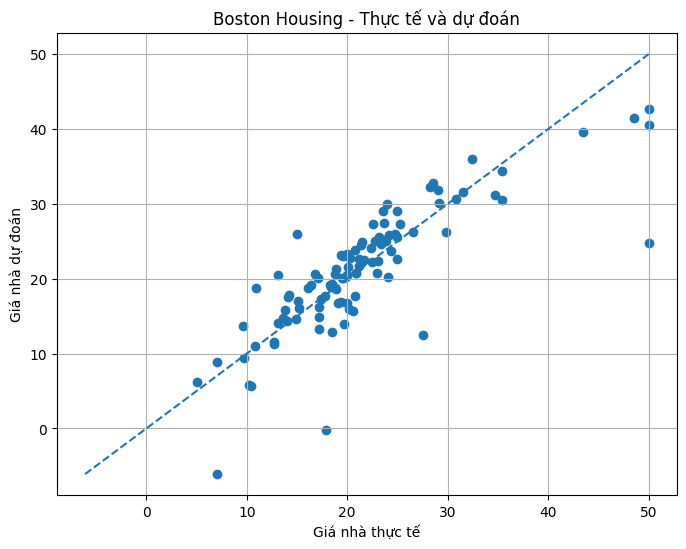

In [6]:
# BTVN3: LINEAR REGRESSION - BOSTON HOUSING
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tải dữ liệu Boston Housing
boston = fetch_openml(name="boston", version=1, as_frame=True)

X = boston.data.copy()
y = boston.target.copy()

# 2. Chuyển dữ liệu về kiểu số
for column in X.columns:
    X[column] = pd.to_numeric(X[column], errors="coerce")

y = pd.to_numeric(y, errors="coerce")

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

# 3. Xem dữ liệu
print("\n5 dòng đầu của X:")
print(X.head())

print("\n5 giá trị giá nhà:")
print(y.head())

# 4. Kiểm tra dữ liệu thiếu
print("\nSố lượng dữ liệu thiếu:")
print(X.isnull().sum())

X = X.fillna(X.median())

# 5. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nSố mẫu train:", len(X_train))
print("Số mẫu test:", len(X_test))

# 6. Tạo mô hình
model = LinearRegression()

# 7. Huấn luyện
model.fit(X_train, y_train)

# 8. Dự đoán
y_pred = model.predict(X_test)

# 9. Đánh giá
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nKẾT QUẢ ĐÁNH GIÁ")
print("Mean Squared Error (MSE):", mse)
print("R2 Score:", r2)

# 10. So sánh giá thực tế và giá dự đoán
result = pd.DataFrame({"Giá thực tế": y_test.to_numpy(), "Giá dự đoán": y_pred})

print("\n20 kết quả đầu tiên:")
print(result.head(20))

# 11. Vẽ biểu đồ
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.xlabel("Giá nhà thực tế")
plt.ylabel("Giá nhà dự đoán")
plt.title("Boston Housing - Thực tế và dự đoán")
plt.grid()
plt.show()